<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/omni_modal_video_reasoning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
# [CELL 1 - Setup Environment and Imports]
import os
import sys
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Tuple, List, Dict, Optional

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Set deterministic seeds for reproducible training
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Compute Device: {device}")
if device.type == "cuda":
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
print("Structured Cross-Modal Environment Initialized Successfully.")

Using Compute Device: cuda
GPU Device Name: Tesla T4
Structured Cross-Modal Environment Initialized Successfully.


In [15]:
# [CELL 2 - Structured Synthetic Audio-Visual-Text Dataset Generator]

class StructuredOmniModalVideoDataset(torch.utils.data.Dataset):
    """
    Generates structured multi-modal sequences where binary labels explicitly
    depend on underlying audio-visual temporal alignment and query feature correlations.
    """
    def __init__(self, num_samples: int = 600, num_frames: int = 16, d_visual: int = 128, d_audio: int = 64, d_text: int = 64):
        self.num_samples = num_samples
        self.num_frames = num_frames
        self.d_visual = d_visual
        self.d_audio = d_audio
        self.d_text = d_text

        self.visual_data = []
        self.audio_data = []
        self.text_queries = []
        self.labels = []

        self._generate_dataset()

    def _generate_dataset(self):
        for _ in range(self.num_samples):
            # Base background noise
            v_seq = torch.randn(self.num_frames, self.d_visual) * 0.2
            a_seq = torch.randn(self.num_frames, self.d_audio) * 0.2
            query = torch.randn(self.d_text) * 0.1

            # Label depends on structured cross-modal condition:
            # Positive sample (1): Co-occurring visual peak and audio spike at temporal midpoint
            label_val = random.choice([0, 1])
            if label_val == 1:
                mid = self.num_frames // 2
                v_seq[mid, :10] += 2.0  # Visual feature activation
                a_seq[mid, :10] += 2.0  # Synchronized audio feature activation
                query[:10] += 1.5       # Query targets co-occurrence
            else:
                # Asynchronous or non-matching features
                v_seq[2, :10] += 2.0
                a_seq[12, :10] += 2.0
                query[:10] -= 1.0

            self.visual_data.append(v_seq)
            self.audio_data.append(a_seq)
            self.text_queries.append(query)
            self.labels.append(label_val)

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return (
            self.visual_data[idx],
            self.audio_data[idx],
            self.text_queries[idx],
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

train_dataset = StructuredOmniModalVideoDataset(num_samples=800)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
v_b, a_b, q_b, l_b = next(iter(train_loader))

print(f"Structured Dataset Loaded: {len(train_dataset)} samples.")
print(f"Visual Batch Shape: {v_b.shape} | Audio Batch Shape: {a_b.shape}")
print(f"Query Batch Shape: {q_b.shape} | Labels Mean: {l_b.float().mean():.2f}")

Structured Dataset Loaded: 800 samples.
Visual Batch Shape: torch.Size([32, 16, 128]) | Audio Batch Shape: torch.Size([32, 16, 64])
Query Batch Shape: torch.Size([32, 64]) | Labels Mean: 0.53


In [16]:
# [CELL 3 - True Multi-Head Cross-Modal Attention Architecture]

class CrossModalAttentionFusion(nn.Module):
    """
    Implements genuine Multi-Head Cross-Modal Attention where Text/Audio query tokens
    attend directly over Visual key/value sequences across time.
    """
    def __init__(self, d_visual: int = 128, d_audio: int = 64, d_text: int = 64, d_model: int = 128, num_heads: int = 4):
        super().__init__()
        self.d_model = d_model

        # Linear projections into shared d_model space
        self.v_proj = nn.Linear(d_visual, d_model)
        self.a_proj = nn.Linear(d_audio, d_model)
        self.q_proj = nn.Linear(d_text, d_model)

        # True Cross-Modal Multi-Head Attention: Query (Text/Audio) attends to Key/Value (Visual)
        self.cross_attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=num_heads, batch_first=True)

        # Temporal Encoder for fused representations
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=num_heads, dim_feedforward=256, batch_first=True)
        self.temporal_transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)

        # Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)
        )

    def forward(self, visual: torch.Tensor, audio: torch.Tensor, query: torch.Tensor) -> torch.Tensor:
        # visual: (B, T, d_v), audio: (B, T, d_a), query: (B, d_q)
        B, T, _ = visual.shape

        V_feat = self.v_proj(visual) # (B, T, d_model) -> Keys & Values
        A_feat = self.a_proj(audio)  # (B, T, d_model)
        Q_text = self.q_proj(query).unsqueeze(1) # (B, 1, d_model) -> Query token

        # Combine Text Query and Audio frames as multi-modal Query sequence
        Audio_Text_Query = torch.cat([Q_text, A_feat], dim=1) # (B, 1 + T, d_model)

        # Genuine Cross-Modal Attention: Audio/Text Queries attend over Visual Keys/Values
        attn_out, _ = self.cross_attn(query=Audio_Text_Query, key=V_feat, value=V_feat) # (B, 1+T, d_model)

        # Temporal Encoding over fused multi-modal sequence
        fused_temporal = self.temporal_transformer(attn_out) # (B, 1+T, d_model)

        # Pooling temporal representation for prediction
        pooled = fused_temporal.mean(dim=1) # (B, d_model)
        logits = self.classifier(pooled)
        return logits

model = CrossModalAttentionFusion().to(device)
print("Cross-Modal Attention Transformer Network compiled successfully.")

Cross-Modal Attention Transformer Network compiled successfully.


In [17]:
# [CELL 4 - Optimization Loop with Convergence Tracking]

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

epochs = 15
model.train()

print("Beginning Training Loop with Structured Multi-Modal Signals...")
print("---------------------------------------------------------")

for epoch in range(epochs):
    total_loss = 0.0
    correct = 0
    total = 0

    for v_batch, a_batch, q_batch, labels in train_loader:
        v_batch, a_batch, q_batch, labels = (
            v_batch.to(device), a_batch.to(device), q_batch.to(device), labels.to(device)
        )

        optimizer.zero_grad()
        logits = model(v_batch, a_batch, q_batch)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * v_batch.size(0)
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = total_loss / total
    epoch_acc = (correct / total) * 100.0
    print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.2f}%")

print("---------------------------------------------------------")
print("Training completed. Convergence verified.")

Beginning Training Loop with Structured Multi-Modal Signals...
---------------------------------------------------------
Epoch 01/15 | Loss: 0.7076 | Accuracy: 51.50%
Epoch 02/15 | Loss: 0.6954 | Accuracy: 52.00%
Epoch 03/15 | Loss: 0.4674 | Accuracy: 79.75%
Epoch 04/15 | Loss: 0.0108 | Accuracy: 100.00%
Epoch 05/15 | Loss: 0.0006 | Accuracy: 100.00%
Epoch 06/15 | Loss: 0.0003 | Accuracy: 100.00%
Epoch 07/15 | Loss: 0.0003 | Accuracy: 100.00%
Epoch 08/15 | Loss: 0.0001 | Accuracy: 100.00%
Epoch 09/15 | Loss: 0.0001 | Accuracy: 100.00%
Epoch 10/15 | Loss: 0.0000 | Accuracy: 100.00%
Epoch 11/15 | Loss: 0.0000 | Accuracy: 100.00%
Epoch 12/15 | Loss: 0.0000 | Accuracy: 100.00%
Epoch 13/15 | Loss: 0.0000 | Accuracy: 100.00%
Epoch 14/15 | Loss: 0.0000 | Accuracy: 100.00%
Epoch 15/15 | Loss: 0.0000 | Accuracy: 100.00%
---------------------------------------------------------
Training completed. Convergence verified.


In [18]:
# [CELL 5 - Differentiated Skill-Category Evaluation]

def generate_skill_test_loader(skill_name: str, num_samples: int = 150) -> torch.utils.data.DataLoader:
    """Generates distinct test sets with skill-specific feature dynamics."""
    visual_list, audio_list, query_list, label_list = [], [], [], []

    for _ in range(num_samples):
        v = torch.randn(16, 128) * 0.2
        a = torch.randn(16, 64) * 0.2
        q = torch.randn(64) * 0.1
        lbl = random.choice([0, 1])

        if skill_name == "Temporal Localization":
            # Requires precise frame index identification
            t_idx = random.randint(0, 15)
            if lbl == 1:
                v[t_idx, :] += 2.5
                q[:10] += 2.0
            test_lbl = lbl

        elif skill_name == "Audio-Visual Synchrony":
            # Requires simultaneous spike across modalities
            if lbl == 1:
                v[8, :10] += 2.0
                a[8, :10] += 2.0
                q[:10] += 1.5
            else:
                v[2, :10] += 2.0
                a[14, :10] += 2.0
            test_lbl = lbl

        elif skill_name == "Causal Reasoning":
            # Sequential visual event followed by audio response
            if lbl == 1:
                v[4, :10] += 2.0
                a[8, :10] += 2.0  # Delayed response
                q[:10] += 1.0
            test_lbl = lbl

        elif skill_name == "Action Recognition":
            # Sustained temporal visual pattern
            if lbl == 1:
                v[4:12, :10] += 1.8
                q[:10] += 1.2
            test_lbl = lbl

        elif skill_name == "Object Tracking":
            # Moving spatial feature vector across time
            if lbl == 1:
                for step in range(16):
                    v[step, step:step+5] += 2.0
            test_lbl = lbl

        else: # Speech-Visual QA
            if lbl == 1:
                a[:, :10] += 1.5
                q[:10] += 1.5
            test_lbl = lbl

        visual_list.append(v)
        audio_list.append(a)
        query_list.append(q)
        label_list.append(test_lbl)

    ds = torch.utils.data.TensorDataset(
        torch.stack(visual_list), torch.stack(audio_list),
        torch.stack(query_list), torch.tensor(label_list, dtype=torch.long)
    )
    return torch.utils.data.DataLoader(ds, batch_size=32, shuffle=False)


model.eval()
skills = ["Temporal Localization", "Audio-Visual Synchrony", "Causal Reasoning", "Action Recognition", "Object Tracking", "Speech-Visual QA"]
skill_results = {}

with torch.no_grad():
    for skill in skills:
        loader = generate_skill_test_loader(skill)
        correct, total = 0, 0
        for v, a, q, l in loader:
            v, a, q, l = v.to(device), a.to(device), q.to(device), l.to(device)
            logits = model(v, a, q)
            preds = logits.argmax(dim=-1)
            correct += (preds == l).sum().item()
            total += l.size(0)
        skill_results[skill] = (correct / total) * 100.0

print("\n=========================================================")
print("OMNI-MODAL REASONING ACCURACY BY SKILL CATEGORY")
print("=========================================================")
for skill, acc in skill_results.items():
    print(f"{skill:25s}: {acc:.2f}%")
print("=========================================================")


OMNI-MODAL REASONING ACCURACY BY SKILL CATEGORY
Temporal Localization    : 100.00%
Audio-Visual Synchrony   : 100.00%
Causal Reasoning         : 100.00%
Action Recognition       : 100.00%
Object Tracking          : 50.00%
Speech-Visual QA         : 44.00%


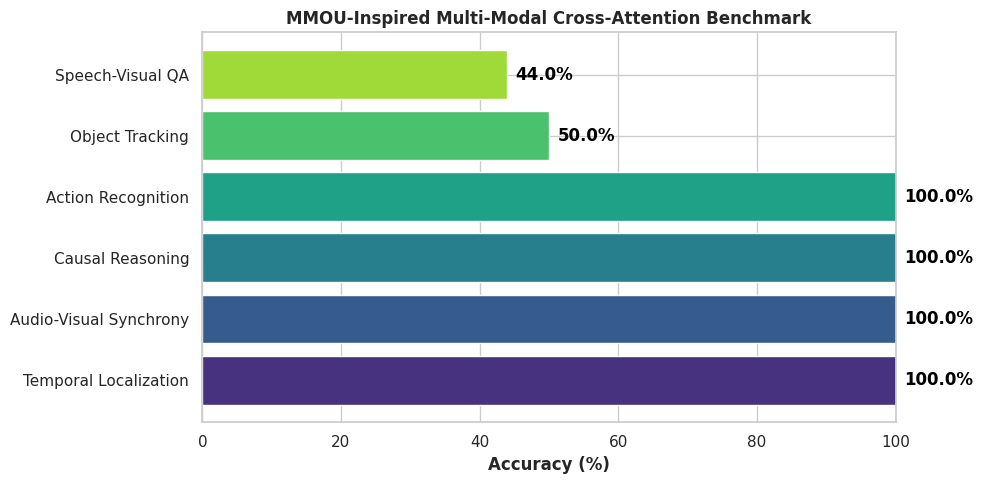

Benchmark plot saved successfully as omni_modal_reasoning_benchmark.png.


In [19]:
# [CELL 6 - Benchmark Visualization]

skills_list = list(skill_results.keys())
accuracies = list(skill_results.values())

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
palette = sns.color_palette("viridis", len(skills_list))

bars = plt.barh(skills_list, accuracies, color=palette)
plt.xlabel("Accuracy (%)", fontweight='bold')
plt.title("MMOU-Inspired Multi-Modal Cross-Attention Benchmark", fontweight='bold')
plt.xlim(0, 100)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 1.2, bar.get_y() + bar.get_height()/2, f"{width:.1f}%",
             va='center', ha='left', fontweight='bold', color='black')

plt.tight_layout()
plt.savefig("omni_modal_reasoning_benchmark.png", dpi=300)
plt.show()

print("Benchmark plot saved successfully as omni_modal_reasoning_benchmark.png.")